<a href="https://colab.research.google.com/github/Ardi-ian/tugas-citra-digital/blob/main/tugas_citra_digital.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sambungkan Drive dan buka foto

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


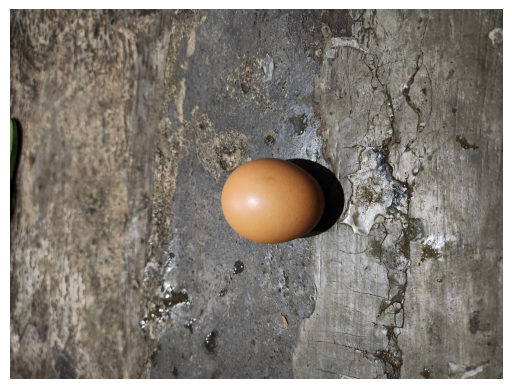

In [25]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os

nama_file = '/content/drive/MyDrive/Tugas/citra-digital/foto.jpg'
img = Image.open(nama_file)
plt.imshow(img); plt.axis('off'); plt.show()

Buktikan gambar = array angka

In [26]:
arr = np.array(img.convert('RGB'))
print('Tipe data :', arr.dtype)
print('Shape     :', arr.shape)   # (tinggi, lebar, 3)
print('Min / Max :', arr.min(), '/', arr.max())

Tipe data : uint8
Shape     : (3000, 4000, 3)
Min / Max : 0 / 255


Zoom ke 8×8 piksel (bukti utama)

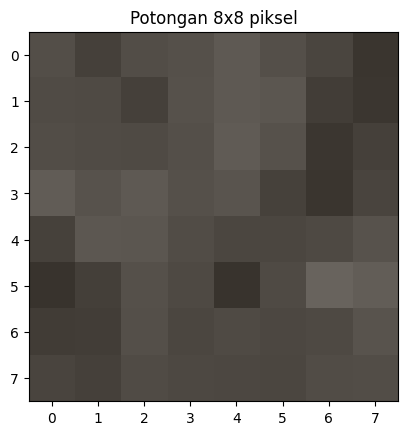

Angka channel Red:
 [[ 83  69  82  85  94  84  74  58]
 [ 80  79  69  86  94  91  66  59]
 [ 82  80  79  84  96  86  59  69]
 [ 97  87  94  85  89  70  58  73]
 [ 70  92  91  81  75  75  78  87]
 [ 56  68  85  78  56  79 104  98]
 [ 65  66  84  75  79  76  78  88]
 [ 73  69  80  77  76  75  81  82]]
Piksel (0,0) [R,G,B]: [83 78 72]


In [27]:
potongan = arr[0:8, 0:8]
plt.imshow(potongan, interpolation='nearest'); plt.title('Potongan 8x8 piksel'); plt.show()
print('Angka channel Red:\n', potongan[:, :, 0])
print('Piksel (0,0) [R,G,B]:', arr[0, 0])

Pisah channel R, G, B

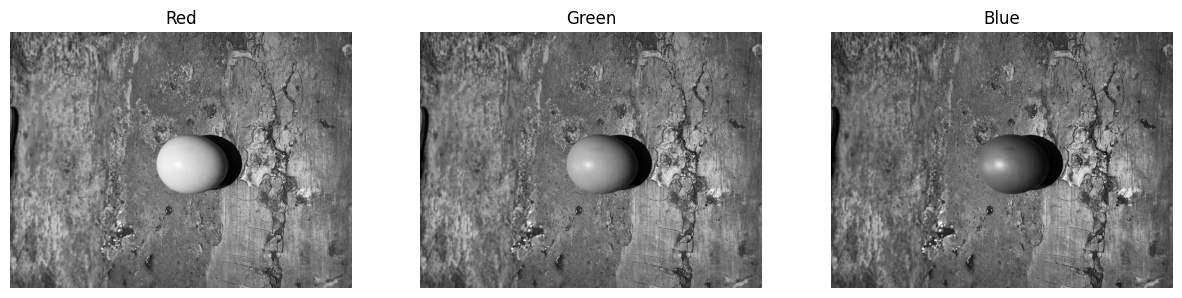

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, nama in enumerate(['Red', 'Green', 'Blue']):
    ax[i].imshow(arr[:, :, i], cmap='gray'); ax[i].set_title(nama); ax[i].axis('off')
plt.show()

Grayscale

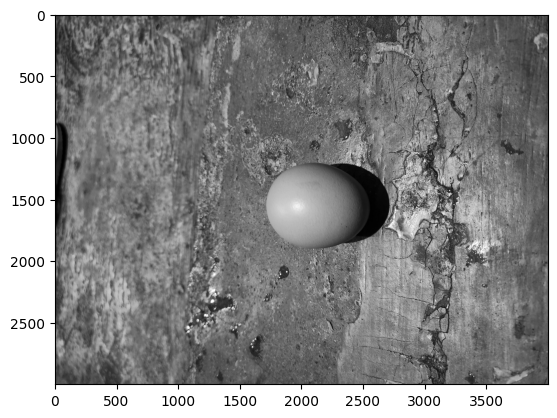

[[78 64 77 80 89]
 [75 74 64 81 89]
 [77 75 74 79 91]
 [92 82 89 80 84]
 [65 87 86 76 70]]


In [29]:
gray = (0.299*arr[:,:,0] + 0.587*arr[:,:,1] + 0.114*arr[:,:,2]).astype(np.uint8)
plt.imshow(gray, cmap='gray'); plt.show()
print(gray[0:5, 0:5])

Gambar dari angka murni

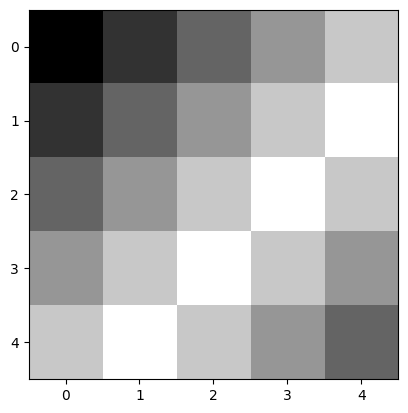

In [30]:
buatan = np.array([[0, 50, 100, 150, 200],
                   [50, 100, 150, 200, 255],
                   [100, 150, 200, 255, 200],
                   [150, 200, 255, 200, 150],
                   [200, 255, 200, 150, 100]], dtype=np.uint8)
plt.imshow(buatan, cmap='gray', interpolation='nearest'); plt.show()

Ubah angka, gambar ikut berubah

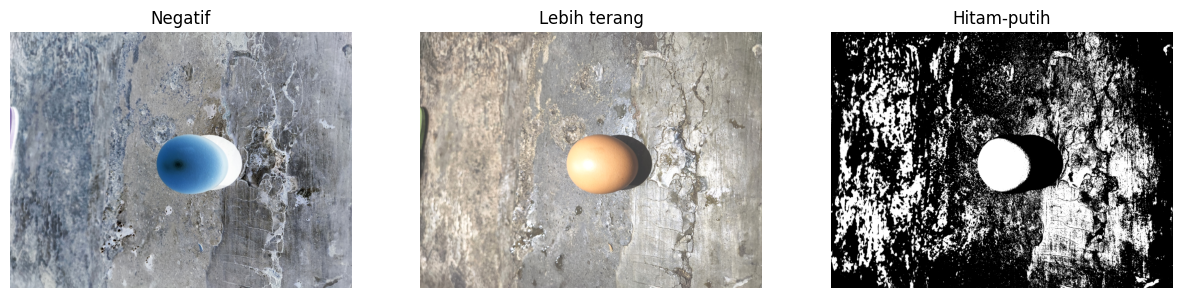

In [31]:
negatif = 255 - arr
terang  = np.clip(arr.astype(int) + 60, 0, 255).astype(np.uint8)
biner   = (gray > 128) * 255

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
hasil = [negatif, terang, biner]
judul = ['Negatif', 'Lebih terang', 'Hitam-putih']
for a, im, t in zip(ax, hasil, judul):
    a.imshow(im, cmap='gray' if t == 'Hitam-putih' else None)
    a.set_title(t); a.axis('off')
plt.show()

Histogram

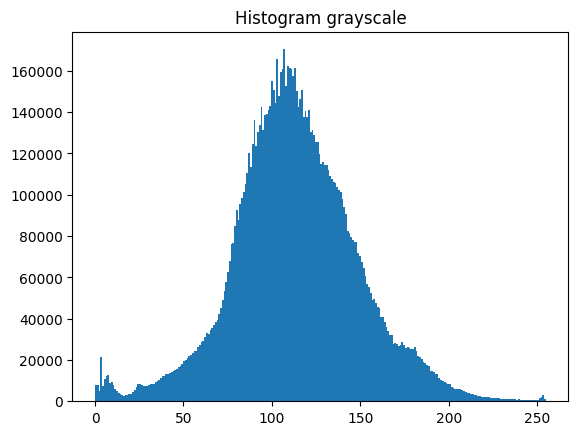

In [32]:
plt.hist(gray.ravel(), bins=256, range=(0, 255))
plt.title('Histogram grayscale'); plt.show()

Metadata dasar dan hitungan

In [33]:
total_piksel = img.size[0] * img.size[1]
print('Format       :', img.format)
print('Mode warna   :', img.mode)
print('Ukuran (px)  :', img.size)
print('DPI          :', img.info.get('dpi'))
print('Ukuran file  : %.1f KB' % (os.path.getsize(nama_file)/1024))
print('Total piksel :', total_piksel)
print('Total angka  :', total_piksel * 3)
print('Ukuran mentah: %.1f KB (tanpa kompresi)' % (total_piksel*3/1024))

Format       : JPEG
Mode warna   : RGB
Ukuran (px)  : (4000, 3000)
DPI          : (72.0, 72.0)
Ukuran file  : 8598.2 KB
Total piksel : 12000000
Total angka  : 36000000
Ukuran mentah: 35156.2 KB (tanpa kompresi)


Metadata EXIF

In [34]:
from PIL.ExifTags import TAGS
exif = img.getexif()
if exif:
    for tag_id, nilai in exif.items():
        print(TAGS.get(tag_id, tag_id), ':', nilai)
else:
    print('Tidak ada EXIF')

ImageWidth : 4000
ImageLength : 3000
GPSInfo : 724
ResolutionUnit : 2
ExifOffset : 238
Make : samsung
Model : SM-S906E
Software : S906EXXSEGZH4
Orientation : 6
DateTime : 2026:10:20 17:46:46
YCbCrPositioning : 1
XResolution : 72.0
YResolution : 72.0
